# Разведка и сборка сводных данных о налоговой задолженности РФ (2020–2022 гг.)

В этом блокноте исследуется структура Раздела 8 Сводного налогового паспорта РФ за 2020–2022 годы и выполняется сборка единого очищенного датасета `passport_debt_rf_2020_2022.csv`. Дополнительно в итоговую таблицу интегрируются данные о доходах консолидированного бюджета из API «Электронного бюджета».


## Шаг 1. Изучение шапки и перечня показателей Раздела 8
Загружаем файл за 2020 год и выводим структуру заголовков и коды строк (801–823), чтобы определить нужные разрезы по налогам и статусам задолженности.


In [1]:
import pandas as pd

path_2020 = r"..\data_raw\passport_rf_2020.xlsx"
df_8 = pd.read_excel(path_2020, sheet_name="Раздел8", header=None)

print("=== ШАПКА РАЗДЕЛА 8 (ПЕРВЫЕ 8 СТРОК) ===")
print(df_8.iloc[:8, :8].to_string())

print("\n=== ВСЕ СТРОКИ РАЗДЕЛА 8 (КОЛОНКИ 0-7) ===")
print(df_8.iloc[8:, :8].dropna(how="all").to_string())


=== ШАПКА РАЗДЕЛА 8 (ПЕРВЫЕ 8 СТРОК) ===
                                                                                                                 0           1                           2                                                       3                                                                       4                                                          5                                           6                      7
0  Раздел 8.Задолженность по налогам и сборам, пеням и налоговым санкциям в бюджетную систему Российской Федерации         NaN                         NaN                                                     NaN                                                                     NaN                                                        NaN                                         NaN                    NaN
1                                                                                             РОССИЙСКАЯ ФЕДЕРАЦИЯ         NaN               

## Шаг 2. Сверка индексов колонок между 2020 и 2021–2022 годами
Проверяем порядок столбцов со статусами взыскания во всех трёх файлах и фиксируем смещение колонки отсроченных платежей в отчётах за 2021–2022 годы.


In [2]:
import pandas as pd

for year, fname in ((2020, "passport_rf_2020.xlsx"), (2021, "passport_rf_2021.xlsx"), (2022, "passport_rf_2022.xlsx")):
    df = pd.read_excel(rf"..\data_raw\{fname}", sheet_name="Раздел8", header=None)
    print(f"=== {year} ГОД: НАЗВАНИЯ КОЛОНОК (ИНДЕКСЫ 2-6) ===")
    for col_idx in range(2, 7):
        col_title = str(df.iloc[5, col_idx]).replace("\n", " ").strip()
        print(f"  Индекс {col_idx}: {col_title}")
    print("Нижние строки таблицы (коды 819-823):")
    print(df.iloc[29:, :7].dropna(how="all").to_string(index=False, header=False))
    print("-" * 50)


=== 2020 ГОД: НАЗВАНИЯ КОЛОНОК (ИНДЕКСЫ 2-6) ===
  Индекс 2: nan
  Индекс 3: Недоимка / Задолженность по пеням и налоговым санкциям
  Индекс 4: Отсроченные (рассроченные) платежи и реструктурированная задолженность
  Индекс 5: Приостановленные к взысканию платежи и мировое соглашение
  Индекс 6: Невозможно к взысканию налоговыми органами
Нижние строки таблицы (коды 819-823):
                          СОВОКУПНАЯ ЗАДОЛЖЕННОСТЬ в консолидированный бюджет Российской Федерации  819  1464636.526  712974.171  65833.853  750574.769  10540.816
                                                                                       кроме того:  NaN          NaN         NaN        NaN         NaN        NaN
                                        ЗАДОЛЖЕННОСТЬ ПО ЕДИНОМУ СОЦИАЛЬНОМУ НАЛОГУ (налог + пени)  820     3544.764    1646.772     232.66    1868.976     30.393
                                ЗАДОЛЖЕННОСТЬ В ГОСУДАРСТВЕННЫЕ ВНЕБЮДЖЕТНЫЕ ФОНДЫ (взносы + пени)  821     1260.215     416.293     

## Шаг 3. Парсинг файлов, объединение с данными бюджета и экспорт в CSV
Извлекаем 12 целевых показателей за 2020–2022 годы, приводим их к единому формату, добавляем поступления консолидированного бюджета РФ и сохраняем результат в `data_processed/passport_debt_rf_2020_2022.csv`.


In [3]:
import os
import pandas as pd

os.makedirs(r"..\data_processed", exist_ok=True)

files_cfg = {
    2020: {
        "path": r"..\data_raw\passport_rf_2020.xlsx",
        "cols": {"Всего_млн_руб": 2, "Недоимка_и_пени_млн_руб": 3, "Отсроченные_млн_руб": 4, "Приостановленные_млн_руб": 5, "Невозможные_млн_руб": 6}
    },
    2021: {
        "path": r"..\data_raw\passport_rf_2021.xlsx",
        "cols": {"Всего_млн_руб": 2, "Недоимка_и_пени_млн_руб": 3, "Приостановленные_млн_руб": 4, "Невозможные_млн_руб": 5, "Отсроченные_млн_руб": 6}
    },
        2022: {
        "path": r"..\data_raw\passport_rf_2022.xlsx",
        "cols": {"Всего_млн_руб": 2, "Недоимка_и_пени_млн_руб": 3, "Приостановленные_млн_руб": 4, "Невозможные_млн_руб": 5, "Отсроченные_млн_руб": 6}
    }

}

budget_income_mln = {
    2020: None,
    2021: 13651770.0,
    2022: 15432733.61
}

target_codes = {
    "801": "Задолженность по налогам и сборам (всего)",
    "802": "Федеральные налоги и сборы",
    "804": "Налог на прибыль организаций",
    "806": "НДС (по товарам, реализуемым в РФ)",
    "807": "НДПИ",
    "808": "НДФЛ",
    "812": "Региональные налоги и сборы",
    "814": "Местные налоги и сборы",
    "817": "Налоги со специальным налоговым режимом",
    "818": "Задолженность по пеням и налоговым санкциям",
    "822": "Задолженность по страховым взносам",
    "823": "Совокупная задолженность по РФ (с учетом страховых взносов)"
}

records = []

for year, cfg in files_cfg.items():
    df = pd.read_excel(cfg["path"], sheet_name="Раздел8", header=None)
    df["clean_code"] = df.iloc[:, 1].astype(str).str.replace(".0", "", regex=False).str.strip()
    
    for code, name in target_codes.items():
        matched = df[df["clean_code"] == code]
        if not matched.empty:
            rec = {
                "Год": year,
                "Код_строки": code,
                "Показатель": name
            }
            for col_name, col_idx in cfg["cols"].items():
                raw_val = matched.iat[0, col_idx]
                val = pd.to_numeric(raw_val, errors="coerce")
                rec[col_name] = 0.0 if pd.isna(val) else round(float(val), 2)
            rec["Поступило_доходов_КБ_РФ_млн_руб"] = budget_income_mln[year]
            records.append(rec)

final_rf = pd.DataFrame(records)
out_path = os.path.join(r"..\data_processed", "passport_debt_rf_2020_2022.csv")
final_rf.to_csv(out_path, index=False, encoding="utf-8-sig")

print(f"Готово! Собрано строк: {len(final_rf)}. Сохранено в {out_path}\n")
print(final_rf[final_rf["Код_строки"] == "823"].to_string(index=False))


Готово! Собрано строк: 36. Сохранено в ..\data_processed\passport_debt_rf_2020_2022.csv

 Год Код_строки                                                  Показатель  Всего_млн_руб  Недоимка_и_пени_млн_руб  Отсроченные_млн_руб  Приостановленные_млн_руб  Невозможные_млн_руб  Поступило_доходов_КБ_РФ_млн_руб
2020        823 Совокупная задолженность по РФ (с учетом страховых взносов)     1830367.44                910017.59            137359.36                 922384.64             11895.64                              NaN
2021        823 Совокупная задолженность по РФ (с учетом страховых взносов)     1988974.55               1237321.19             82090.27                 777311.05             18226.72                      13651770.00
2022        823 Совокупная задолженность по РФ (с учетом страховых взносов)     2528009.50               1636833.94            110607.48                 927226.68             13470.27                      15432733.61


## Шаг 4. Визуальная проверка итоговых показателей по строке 823
Строим контрольную столбчатую диаграмму динамики совокупного долга, недоимки и приостановленной задолженности для первичной валидации собранных цифр.


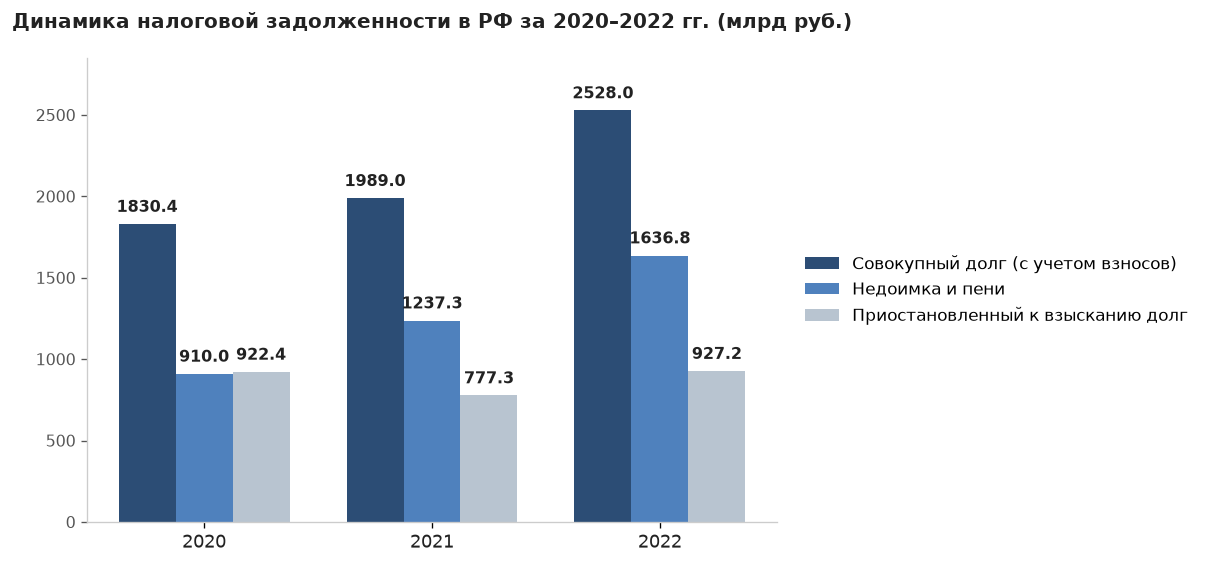

In [4]:
import os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams["font.sans-serif"] = "DejaVu Sans"

df = pd.read_csv(os.path.join(r"..\data_processed", "passport_debt_rf_2020_2022.csv"))
df["Код_строки"] = df["Код_строки"].astype(str).str.strip()

df_823 = df[df["Код_строки"] == "823"].sort_values("Год").copy()
years_1 = df_823["Год"].astype(str)
x1 = range(len(years_1))
w1 = 0.25

total_1 = df_823["Всего_млн_руб"] / 1000
unsettled_1 = df_823["Недоимка_и_пени_млн_руб"] / 1000
suspended_1 = df_823["Приостановленные_млн_руб"] / 1000

fig1, ax1 = plt.subplots(figsize=(10, 4.8), dpi=120)
b1_1 = ax1.bar([i - w1 for i in x1], total_1, w1, label="Совокупный долг (с учетом взносов)", color="#2C4D75")
b1_2 = ax1.bar(x1, unsettled_1, w1, label="Недоимка и пени", color="#4F81BD")
b1_3 = ax1.bar([i + w1 for i in x1], suspended_1, w1, label="Приостановленный к взысканию долг", color="#B8C4D0")

for bars in (b1_1, b1_2, b1_3):
    for bar in bars:
        h = bar.get_height()
        ax1.annotate(
            f"{h:.1f}",
            xy=(bar.get_x() + bar.get_width() / 2, h),
            xytext=(0, 5),
            textcoords="offset points",
            ha="center",
            va="bottom",
            fontsize=9.5,
            fontweight="bold",
            color="#222222",
        )

ax1.set_title("Динамика налоговой задолженности в РФ за 2020–2022 гг. (млрд руб.)", fontsize=12, fontweight="bold", pad=18, color="#222222")
ax1.set_xticks(list(x1))
ax1.set_xticklabels(years_1, fontsize=11, color="#222222")
ax1.set_ylim(0, 2850)
ax1.tick_params(axis="y", labelsize=9.5, colors="#555555")
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.spines["left"].set_color("#CCCCCC")
ax1.spines["bottom"].set_color("#CCCCCC")
ax1.legend(frameon=False, loc="center left", bbox_to_anchor=(1.02, 0.5), fontsize=10)

plt.tight_layout()
plt.show()
